# CNN - CIFAR-10

In [14]:
!uv pip install -P 'kpihx-lab' 'kpihx-lab'

from lab.kit import Context

Context.display()

Using Python 3.12.12 environment at: /home/kpihx/Labs/Explore/lab/.venv
Resolved 90 packages in 1.92s                                        
Audited 90 packages in 0.89ms

  πππ    πππ               πππ    πππ   OS      : Linux 7.0.0-38-generic (x86_64)
  πππ  ππππ    KπX-Labs     πππ  πππ   Host    : KpihX-Ubuntu
  πππ πππ    ππππππππππππ    ππππππ   Runtime : local
  ππππππ       πππ  πππ       ππππ   Python  : 3.12.12 @ /home/kpihx/Labs/Explore/lab/.venv/bin/python
  πππππππ      πππ  πππ      πππππ   Base    : /home/kpihx/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu
  πππ  πππ     πππ  πππ      ππππππ   Root    : /home/kpihx/Labs/Explore/lab
  πππ   ππππ   πππ  πππ     πππ  πππ   Device  : Intel XPU (Intel(R) Arc(TM) Graphics)
  πππ    ππππ πππ    ππππ  πππ    πππ   



In [15]:
# import kagglehub
# import pickle
# import numpy as np

# from pathlib import Path 

# KAGGLE_DATASET = "pankrzysiu/cifar10-python"
# dataset_dir = Path(kagglehub.dataset_download(KAGGLE_DATASET)) / "cifar-10-batches-py"

# with open(dataset_dir / "batches.meta", "rb") as f:
#     classes = [str(c) for c in pickle.load(f, encoding='latin1')["label_names"]]

# x_train_list, y_train_list = [], []
# for i in range(1, 6):
#     with open(dataset_dir / f"data_batch_{i}", "rb") as f:
#         batch = pickle.load(f, encoding='latin1')
#         x_train_list.append(batch["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1))
#         y_train_list.append(batch["labels"])

# x_train_full = np.concatenate(x_train_list, axis=0)
# y_train_full = np.concatenate(y_train_list, axis=0).astype(np.int8)

# with open(dataset_dir / "test_batch", "rb") as f:
#     test_batch = pickle.load(f, encoding='latin1')
#     x_test_full = test_batch["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
#     y_test_full = np.array(test_batch["labels"], dtype=np.int8)

In [16]:
import kagglehub
import numpy as np

from pathlib import Path 
from torchvision.datasets import CIFAR10

KAGGLE_DATASET = "pankrzysiu/cifar10-python"
dataset_dir = Path(kagglehub.dataset_download(KAGGLE_DATASET))

train = CIFAR10(root=dataset_dir, download=False, train=True)
test = CIFAR10(root=dataset_dir, download=False, train=False)
classes = train.classes 

x_train_full, y_train_full = train.data, np.array(train.targets, dtype=np.uint8)
x_test_full, y_test_full = test.data, np.array(test.targets, dtype=np.uint8)

In [ ]:
from lab.kit import show 

N_TRAIN_FULL, H, W, N_CHANNELS = x_train_full.shape 
N_TEST_FULL = len(x_test_full)
N_CLASSES = len(classes)

SEED = 0
N_TRAIN = N_TRAIN_FULL // 100
N_TEST = N_TEST_FULL // 100

sample_rng = np.random.default_rng(SEED)
idx_train = sample_rng.choice(N_TRAIN_FULL, N_TRAIN, replace=False)
idx_test = sample_rng.choice(N_TEST_FULL, N_TEST, replace=False)
x_train = x_train_full[idx_train]
x_test = x_test_full[idx_test]
y_train = y_train_full[idx_train]
y_test = y_test_full[idx_test]

show(N_TRAIN_FULL, N_TEST_FULL, full=True)
show(N_TRAIN, N_TEST, N_CHANNELS, H, W, N_CLASSES, full=True)
show(x_train, y_train, x_test, y_test, classes)

# y_train_counts = np.bincount(y_train)
# y_test_counts = np.bincount(y_test)
# show(y_train_counts, y_test_counts, full=True)

y_train_vals, y_train_counts = np.unique(y_train, return_counts=True)
y_test_vals, y_test_counts = np.unique(y_test, return_counts=True)

y_train_uniques = dict(zip(y_train_vals, y_train_counts))
y_test_uniques = dict(zip(y_test_vals, y_test_counts))

show(y_train_uniques, y_test_uniques, full=True)

=== N_TRAIN_FULL ===
type=builtins.int
nbytes=28 B


50000

=== N_TEST_FULL ===
type=builtins.int
nbytes=28 B


10000

=== N_TRAIN ===
type=builtins.int
nbytes=28 B


...

10

=== x_train ===
type=numpy.ndarray
shape=(500, 32, 32, 3)
numel=1,536,000
len=500
dtype=uint8
nbytes=1.5 MB (1,536,000 B)
device=cpu
=== y_train ===
type=numpy.ndarray
shape=(500,)
numel=500
len=500
dtype=uint8
nbytes=500 B
device=cpu
=== x_test ===
type=numpy.ndarray
shape=(100, 32, 32, 3)
numel=307,200
len=100
dtype=uint8
nbytes=300.0 KB (307,200 B)
device=cpu
=== y_test ===
type=numpy.ndarray
shape=(100,)
numel=100
len=100
dtype=uint8
nbytes=100 B
device=cpu
=== classes ===
type=builtins.list
numel=10
len=10
nbytes=152 B
=== y_train_uniques ===
type=builtins.dict
numel=10
len=10
nbytes=352 B


{np.uint8(0): np.int64(68),
 np.uint8(1): np.int64(48),
 np.uint8(2): np.int64(45),
 np.uint8(3): np.int64(53),
 np.uint8(4): np.int64(51),
 np.uint8(5): np.int64(58),
 np.uint8(6): np.int64(52),
 np.uint8(7): np.int64(46),
 np.uint8(8): np.int64(43),
 np.uint8(9): np.int64(36)}

=== y_test_uniques ===
type=builtins.dict
numel=10
len=10
nbytes=352 B


{np.uint8(0): np.int64(12),
 np.uint8(1): np.int64(7),
 np.uint8(2): np.int64(10),
 np.uint8(3): np.int64(8),
 np.uint8(4): np.int64(14),
 np.uint8(5): np.int64(9),
 np.uint8(6): np.int64(9),
 np.uint8(7): np.int64(13),
 np.uint8(8): np.int64(4),
 np.uint8(9): np.int64(14)}

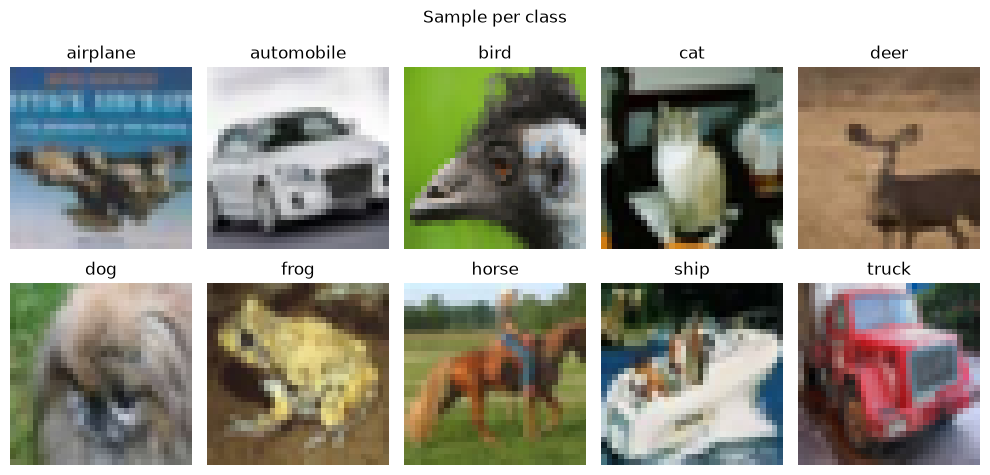

In [18]:
import matplotlib.pyplot as plt 

preview_rng = np.random.default_rng(SEED)

fig, axs = plt.subplots(2, 5, figsize=(10, 5))

for ax, (k, label) in zip(axs.flatten(), enumerate(classes)):
    idx = preview_rng.choice(np.where(y_train == k)[0])
    sample = x_train[idx]
    ax.imshow(sample)
    ax.set_title(label)
    ax.axis("off")

plt.suptitle("Sample per class")
plt.tight_layout()

In [19]:
# import torch 

# if hasattr(torch, 'xpu') and torch.xpu.is_available():
#     device = 'xpu:0'
# elif torch.cuda.is_available():
#     device = 'cuda:0'
# else:
#     device = 'cpu'

# print(device)

In [20]:
import torch 

device = Context.device()

print(device)

xpu:0


In [21]:
from torchvision.transforms import v2

x_train_t = torch.from_numpy(x_train).permute(0, 3, 1, 2).to(device)
y_train_t = torch.from_numpy(y_train).to(device)
x_test_t = torch.from_numpy(x_test).permute(0, 3, 1, 2).to(device)
y_test_t = torch.from_numpy(y_test).to(device)

show(x_train_t, y_train_t, x_test_t, y_test_t)

scaled = x_train_t.div(255.0)
mean_t = scaled.mean(dim=(0, 2, 3))
std_t = scaled.std(dim=(0, 2, 3), unbiased=False)
del scaled

show(mean_t, std_t)

normalize = v2.Compose([
    v2.ToDtype(torch.float32,scale=True),
    v2.Normalize(mean=mean_t, std=std_t),
])

x_train_n = normalize(x_train_t)
x_test_n = normalize(x_test_t)

show(x_train_n, x_test_n)

=== x_train_t ===
type=torch.Tensor
shape=(500, 3, 32, 32)
numel=1,536,000
len=500
dtype=torch.uint8
nbytes=1.5 MB (1,536,000 B)
device=xpu:0
requires_grad=False leaf=True
grad_fn=None
=== y_train_t ===
type=torch.Tensor
shape=(500,)
numel=500
len=500
dtype=torch.uint8
nbytes=500 B
device=xpu:0
requires_grad=False leaf=True
grad_fn=None
=== x_test_t ===
type=torch.Tensor
shape=(100, 3, 32, 32)
numel=307,200
len=100
dtype=torch.uint8
nbytes=300.0 KB (307,200 B)
device=xpu:0
requires_grad=False leaf=True
grad_fn=None
=== y_test_t ===
type=torch.Tensor
shape=(100,)
numel=100
len=100
dtype=torch.uint8
nbytes=100 B
device=xpu:0
requires_grad=False leaf=True
grad_fn=None
=== mean_t ===
type=torch.Tensor
shape=(3,)
numel=3
len=3
dtype=torch.float32
nbytes=12 B
device=xpu:0
requires_grad=False leaf=True
grad_fn=None
=== std_t ===
type=torch.Tensor
shape=(3,)
numel=3
len=3
dtype=torch.float32
nbytes=12 B
device=xpu:0
requires_grad=False leaf=True
grad_fn=None
=== x_train_n ===
type=torch.Tensor

In [22]:
transforms = {
    "RandomCrop": v2.RandomCrop((H, W), padding=4, padding_mode='reflect'),
    "RandomHorizontalFlip": v2.RandomHorizontalFlip(p=0.5),
    "RandomErasing": v2.RandomErasing(p=0.5, value='random', scale=(0.02, 0.20))
}

augment = v2.Compose(tuple(transforms.values()))

show(augment.transforms, full=True)

=== tuple ===
type=builtins.tuple
numel=3
len=3
nbytes=64 B


(RandomCrop(size=(32, 32), padding=[4, 4, 4, 4], pad_if_needed=False, fill=0, padding_mode=reflect),
 RandomHorizontalFlip(p=0.5),
 RandomErasing(p=0.5, scale=(0.02, 0.2), ratio=(0.3, 3.3), inplace=False))

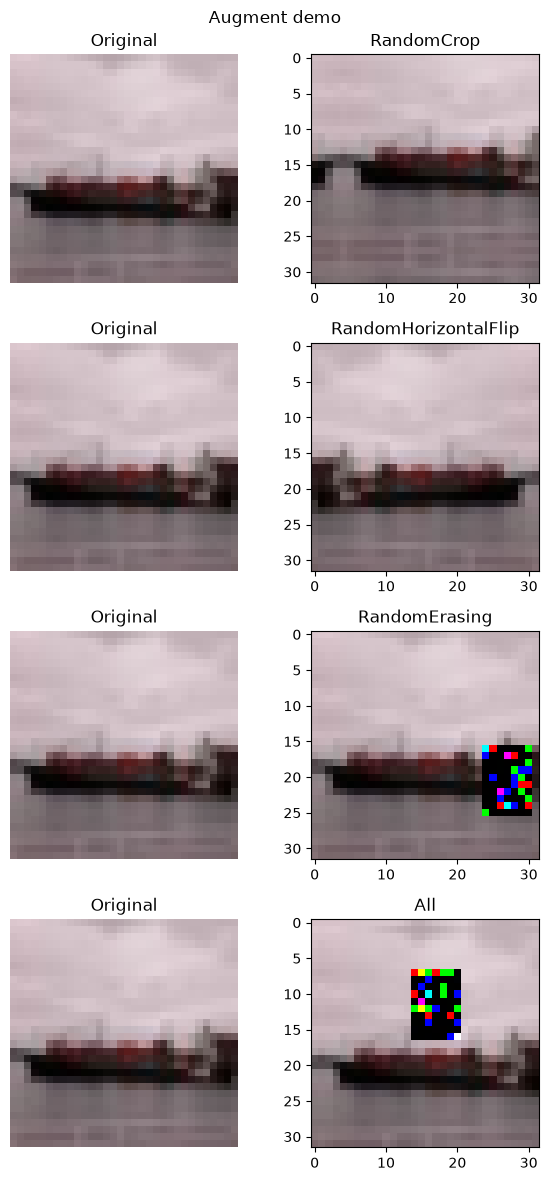

In [23]:
# Demo augments
demo_rng = np.random.default_rng(SEED)
idx = demo_rng.choice(N_TRAIN)
sample = x_train[idx]
sample_t = x_train_t[idx]

transforms.update({"All": augment})

n_transforms = len(transforms)
# generator = torch.Generator().manual_seed(SEED)
torch.manual_seed(SEED)

fig, axs = plt.subplots(n_transforms, 2, figsize=(6, 3 * n_transforms))
axs[0, 0].imshow(sample)
axs[0, 0].set_title("Original")

for k, (transform_name, transform) in enumerate(transforms.items()):
    axs[k, 0].imshow(sample)
    axs[k, 0].set_title("Original")
    axs[k, 0].axis('off')
    out = transform(sample_t).cpu().numpy().transpose(1, 2, 0)
    axs[k, 1].imshow(out)
    axs[k, 1].set_title(transform_name)
    # axs[k, 1].axis('off')

plt.suptitle("Augment demo")
plt.tight_layout()

In [24]:
import torch.nn as nn 

class PlainCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential( # The calibration layer
            nn.Conv2d(N_CHANNELS, 32, 3, 1, 1, bias=False), # no bias since a present one would be cancel by the batchnorm after
            nn.BatchNorm2d(32),
            nn.ReLU(True), # To directly replace negative values of the previous layer by 0, reducing space consumption
        )

        self.body = nn.Sequential(
            nn.Conv2d(32, 32, 3, 1, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(True),
            nn.MaxPool2d(2), 

            nn.Conv2d(32, 64, 3, 1, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.Conv2d(64, 64, 3, 1, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, 1, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.Conv2d(128, 128, 3, 1, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
        )

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), # We avoid flattening the whole representation which will cost more
            nn.Flatten(),
            # nn.Dropout(0.2),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.head(self.body(self.stem(x)))        

In [25]:
import torch.nn.functional as F 

class Block(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)

        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.short = nn.Sequential()
        if stride != 1 or cin != cout:
            self.short = nn.Sequential(
                nn.Conv2d(cin, cout, 1, stride, bias=False),
                nn.BatchNorm2d(cout)
            )

    def forward(self, x):
        out1 = F.relu(self.bn1(self.conv1(x)), True)
        out = F.relu(self.bn2(self.conv2(out1)), True)
        return out + self.short(x)

class ResNet20(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(N_CHANNELS, 16, 3, 1, 1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(True),
        )

        layers, cin = [], 16
        couts = (16, 32, 64) # 3 groups to deeply work at the same resolution in a given group
        strides = (1, 2, 2)
        for cout, stride in zip(couts, strides):
            # groups of 3 block
            for k in range(3):
                block = Block(cin, cout, stride if k == 0 else 1)
                layers.append(block)
                cin = cout

        self.body = nn.Sequential(
            *layers
        )

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            # nn.Dropout(0.2),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        out =  self.head(self.body(self.stem(x)))
        return out

In [26]:
from lab.ai.torch import init_kaiming
from copy import deepcopy

plain_cnn = PlainCNN().to(device)
resnet_cnn = ResNet20().to(device)

plain_cnn.apply(init_kaiming)
resnet_cnn.apply(init_kaiming)

plain_params = tuple(plain_cnn.parameters())
resnet_params = tuple(resnet_cnn.parameters())

plain_init_state = deepcopy(plain_cnn.state_dict())
resnet_init_state = deepcopy(resnet_cnn.state_dict())

show(plain_cnn, resnet_cnn)
# show(plain_params, resnet_params, full=True)
# show(plain_state, resnet_state)

=== plain_cnn ===
type=__main__.PlainCNN
nbytes=48 B

[Layers & Parameters] total=288,746 (trainable=288,746)
  • stem (Sequential): 928 params (trainable=928)
  • body (Sequential): 286,528 params (trainable=286,528)
  • head (Sequential): 1,290 params (trainable=1,290)
=== resnet_cnn ===
type=__main__.ResNet20
nbytes=48 B

[Layers & Parameters] total=272,474 (trainable=272,474)
  • stem (Sequential): 464 params (trainable=464)
  • body (Sequential): 271,360 params (trainable=271,360)
  • head (Sequential): 650 params (trainable=650)


In [27]:
import json

from datetime import datetime
from time import perf_counter

from lab.ai.torch import FocalLoss, sync

output_dir = Context.resolve(Path("assets/outputs/cnn-cifar10/"))
output_dir.mkdir(parents=True, exist_ok=True)

TRAIN_CONFIG = {
    "n_epochs": 250,
    "n_batches": 128,
    "lr": 0.1,
    "momentum": 0.9,
    "weight_decay": 5e-4,
    "eval_freq": 10,
}

# criterion = nn.CrossEntropyLoss(label_smoothing=0.1) # To avoid overconfidence replacing the classic p_i by a smooth version q_i = (1 - eps) * p_i + eps / N_CLASSES
criterion = FocalLoss(gamma=1.5)

def train(model:nn.Module, train_dir:Path, train_config=TRAIN_CONFIG):
    shuffle_generator = torch.Generator(device=device)
    shuffle_generator.manual_seed(SEED+1) # To avoid any correlation with for exple the augment which will use global generator with seed SEED
    
    optim = torch.optim.SGD(
        model.parameters(), 
        lr=train_config["lr"],
        momentum=train_config["momentum"],
        weight_decay=train_config["weight_decay"],
        nesterov=True
    )

    # Robin-monro condition applied on learning rate
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=train_config["n_epochs"])

    hists = {
        "losses": [],
        "train_accs": [],
    }

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    run_dir = Path(train_dir) / stamp
    run_dir.mkdir(parents=True, exist_ok=True)
    last_dir = Path(train_dir) / "last"
    last_path = run_dir / "epoch_last.pt"
    
    meta = {
        "model": type(model).__name__,
        "stamp": stamp,
        "train_config": dict(train_config),
        "seed": SEED,
        "n_train": N_TRAIN,
        "n_test": N_TEST,
        "device": str(device),
        "criterion": type(criterion).__name__,
        "criterion_args": {
            "gamma": getattr(criterion, "gamma", None),
        },
        "optim": type(optim).__name__,
        "scheduler": type(scheduler).__name__,
        "context": dict(Context.info())
    }
    meta_path = run_dir / "meta.json"
    meta_path.write_text(json.dumps(meta, indent=2), encoding="utf-8")

    sync() # To avoid any noise than can be due to operations still in gpu queue
    t0 = perf_counter()
    for epoch in range(1, 1+train_config["n_epochs"]):
        model.train()
        loss_epoch = 0.0
        corrects = 0

        order = torch.randperm(N_TRAIN, device=device, generator=shuffle_generator)
        for i in range(0, N_TRAIN, train_config["n_batches"]):
            idx = order[i: i+train_config["n_batches"]]
            x_batch, y_batch = x_train_n[idx], y_train_t[idx]
            logits = model(augment(x_batch))
            loss = criterion(logits, y_batch)
            
            optim.zero_grad()
            loss.backward()
            optim.step()

            if epoch % train_config["eval_freq"] == 0 or epoch == train_config["n_epochs"]:
                with torch.no_grad():
                    loss_epoch += loss.item() * len(idx)
                    corrects += (logits.argmax(1) == y_batch).sum().item()
                
        scheduler.step()
        if epoch % train_config["eval_freq"] == 0 or epoch == train_config["n_epochs"]:
            loss_epoch /= N_TRAIN
            corrects /= N_TRAIN
            hists["losses"].append(loss_epoch)
            hists["train_accs"].append(corrects)
            print(f"epoch: {epoch}/{train_config['n_epochs']} | loss: {loss_epoch} | train_acc: {corrects}")

        if (epoch >= train_config["n_epochs"] // 2) and (epoch % train_config["eval_freq"] == 0 or epoch > train_config["n_epochs"] - train_config["eval_freq"]):
            epoch_path = run_dir / f"epoch_{epoch}.pt"
            run = {
                "epoch": epoch,
                "model": model.state_dict(),
                "optim": optim.state_dict(),
                "scheduler": scheduler.state_dict(),
                "hists": hists,
            }
            
            torch.save(run, epoch_path)
            last_path.unlink(missing_ok=True)
            last_path.symlink_to(epoch_path.name)
            last_dir.unlink(missing_ok=True)
            last_dir.symlink_to(run_dir.name)

    sync() # We wait for the gpu to have totally ended
    wall = perf_counter() - t0
    meta["wall_time_s"] = wall
    meta["wall_time_per_epochs"] = wall / train_config["n_epochs"]
    meta_path.write_text(json.dumps(meta, indent=2))

    return hists, meta


In [28]:
print("=== Training PlainCNN ===")

plain_dir = output_dir / "plain_cnn"

plain_cnn.load_state_dict(plain_init_state)

plain_config = {
    "n_epochs": 50,
    "n_batches": 128,
    "lr": 0.1,
    "momentum": 0.9,
    "weight_decay": 5e-4,
    "eval_freq": 10,
}

plain_config = TRAIN_CONFIG

hists_plain, meta_plain = train(plain_cnn, plain_dir, plain_config)

print(f"PlainCNN completed after {meta_plain["wall_time_s"]} s")

=== Training PlainCNN ===
epoch: 10/250 | loss: 1.1638540544509888 | train_acc: 0.388
epoch: 20/250 | loss: 0.7728866906166076 | train_acc: 0.566
epoch: 30/250 | loss: 0.6191984581947326 | train_acc: 0.642
epoch: 40/250 | loss: 0.45839316177368167 | train_acc: 0.692
epoch: 50/250 | loss: 0.2788697295188904 | train_acc: 0.81
epoch: 60/250 | loss: 0.23934761190414428 | train_acc: 0.848
epoch: 70/250 | loss: 0.19208571314811707 | train_acc: 0.888
epoch: 80/250 | loss: 0.11288552606105805 | train_acc: 0.934
epoch: 90/250 | loss: 0.14415663331747056 | train_acc: 0.916
epoch: 100/250 | loss: 0.06730088573694229 | train_acc: 0.958
epoch: 110/250 | loss: 0.05389964208006859 | train_acc: 0.958
epoch: 120/250 | loss: 0.09004711472988129 | train_acc: 0.932
epoch: 130/250 | loss: 0.059778282076120376 | train_acc: 0.954
epoch: 140/250 | loss: 0.020122917018830778 | train_acc: 0.99
epoch: 150/250 | loss: 0.06606945475935935 | train_acc: 0.952
epoch: 160/250 | loss: 0.024117128197103738 | train_acc: 

In [ ]:
print("=== Training ResNet20 ===")

resnet_dir = output_dir / "resnet_cnn"

resnet_cnn.load_state_dict(resnet_init_state)

resnet_config = {
    "n_epochs": 50,
    "n_batches": 128,
    "lr": 0.1,
    "momentum": 0.9,
    "weight_decay": 5e-4,
    "eval_freq": 10,
}

resnet_config = TRAIN_CONFIG

hists_resnet, meta_resnet = train(resnet_cnn, resnet_dir, resnet_config)

print(f"ResNet completed after {meta_resnet["wall_time_s"]} s")

=== Training ResNet20 ===
epoch: 10/250 | loss: 1.3008479862213134 | train_acc: 0.392
epoch: 20/250 | loss: 1.055919062614441 | train_acc: 0.46
epoch: 30/250 | loss: 0.8911247735023499 | train_acc: 0.508
epoch: 40/250 | loss: 0.7672310094833374 | train_acc: 0.574
epoch: 50/250 | loss: 0.6069384803771972 | train_acc: 0.624
epoch: 60/250 | loss: 0.44023235368728636 | train_acc: 0.77
epoch: 70/250 | loss: 0.44266180753707884 | train_acc: 0.764
epoch: 80/250 | loss: 0.35915216875076295 | train_acc: 0.782
epoch: 90/250 | loss: 0.1409967669248581 | train_acc: 0.906
epoch: 100/250 | loss: 0.1866584126353264 | train_acc: 0.886
epoch: 110/250 | loss: 0.11611082708835602 | train_acc: 0.926
epoch: 120/250 | loss: 0.11964927589893341 | train_acc: 0.916
epoch: 130/250 | loss: 0.15235113179683685 | train_acc: 0.89
epoch: 140/250 | loss: 0.04820782977342605 | train_acc: 0.976
epoch: 150/250 | loss: 0.06650459951162338 | train_acc: 0.962
epoch: 160/250 | loss: 0.026030248552560805 | train_acc: 0.986
e

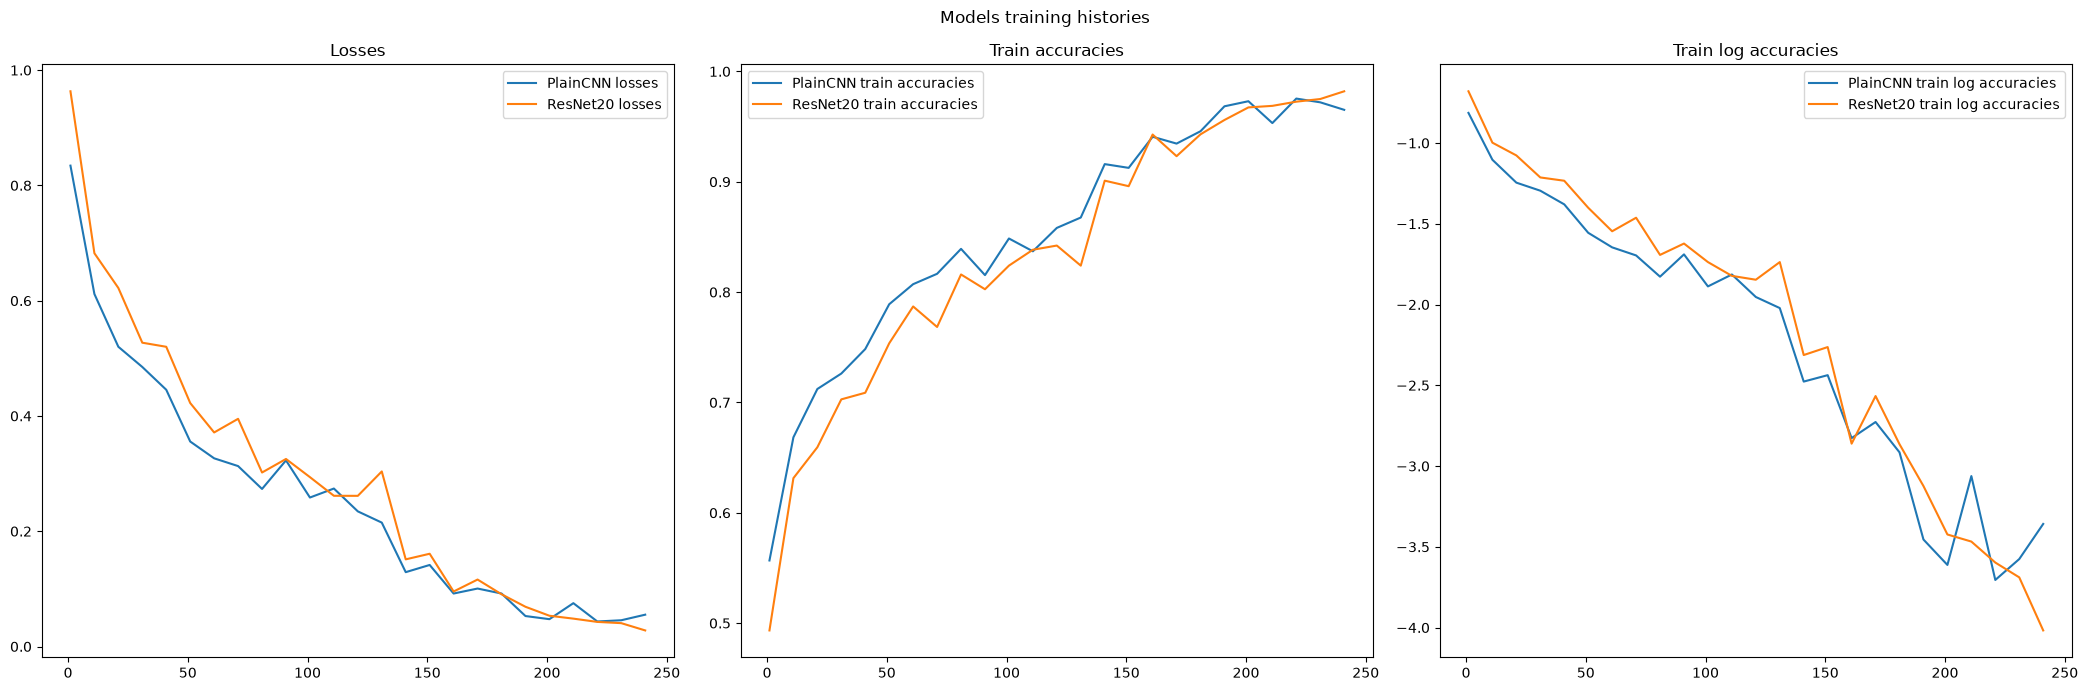

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(21, 7))

xs_plain = np.arange(plain_config["eval_freq"], plain_config["n_epochs"]+1, plain_config["eval_freq"])
train_accs_log_plain = np.log(1 - np.array(hists_plain["train_accs"]))
axs[0].plot(xs_plain, hists_plain["losses"], label="PlainCNN losses")
axs[1].plot(xs_plain, hists_plain["train_accs"], label="PlainCNN train accuracies")
axs[2].plot(xs_plain, train_accs_log_plain, label="PlainCNN train log accuracies")

xs_resnet = np.arange(resnet_config["eval_freq"], resnet_config["n_epochs"]+1, resnet_config["eval_freq"])
train_accs_log_resnet = np.log(1 - np.array(hists_resnet["train_accs"]))
axs[0].plot(xs_resnet, hists_resnet["losses"], label="ResNet20 losses")
axs[1].plot(xs_resnet, hists_resnet["train_accs"], label="ResNet20 train accuracies")
axs[2].plot(xs_resnet, train_accs_log_resnet, label="ResNet20 train log accuracies")

axs[0].set_title("Losses")
axs[0].legend()
axs[1].set_title("Train accuracies")
axs[1].legend()
axs[2].set_title("Train log accuracies")
axs[2].legend()

plt.suptitle("Models training histories")
plt.tight_layout()

In [ ]:
plain_path = plain_dir / "last" / "epoch_last.pt"
plain_run = torch.load(plain_path, map_location=device, weights_only=False)
plain_state = plain_run["model"]
plain_cnn.load_state_dict(plain_state)

resnet_path = resnet_dir / "last" / "epoch_last.pt"
resnet_run = torch.load(resnet_path, map_location=device, weights_only=False)
resnet_state = resnet_run["model"]
resnet_cnn.load_state_dict(resnet_state)

<All keys matched successfully>

=== PlainCNN Eval ===
Loss: 0.594679057598114
MCC: 0.7823817208060055
AVG-PR: 0.8762504619409315
PR-AUC: 0.8754376621479304
Classification report
              precision    recall  f1-score   support

    airplane       0.78      0.86      0.82       101
  automobile       0.94      0.93      0.94       102
        bird       0.76      0.75      0.75        95
         cat       0.69      0.72      0.70       111
        deer       0.75      0.72      0.73       100
         dog       0.66      0.72      0.68        88
        frog       0.81      0.85      0.83        95
       horse       0.87      0.74      0.80       101
        ship       0.86      0.86      0.86       103
       truck       0.94      0.88      0.91       104

    accuracy                           0.80      1000
   macro avg       0.81      0.80      0.80      1000
weighted avg       0.81      0.80      0.80      1000

       class   avg_pr   pr_auc
    airplane   0.8610   0.8594
  automobile   0.9809   0.9809
  

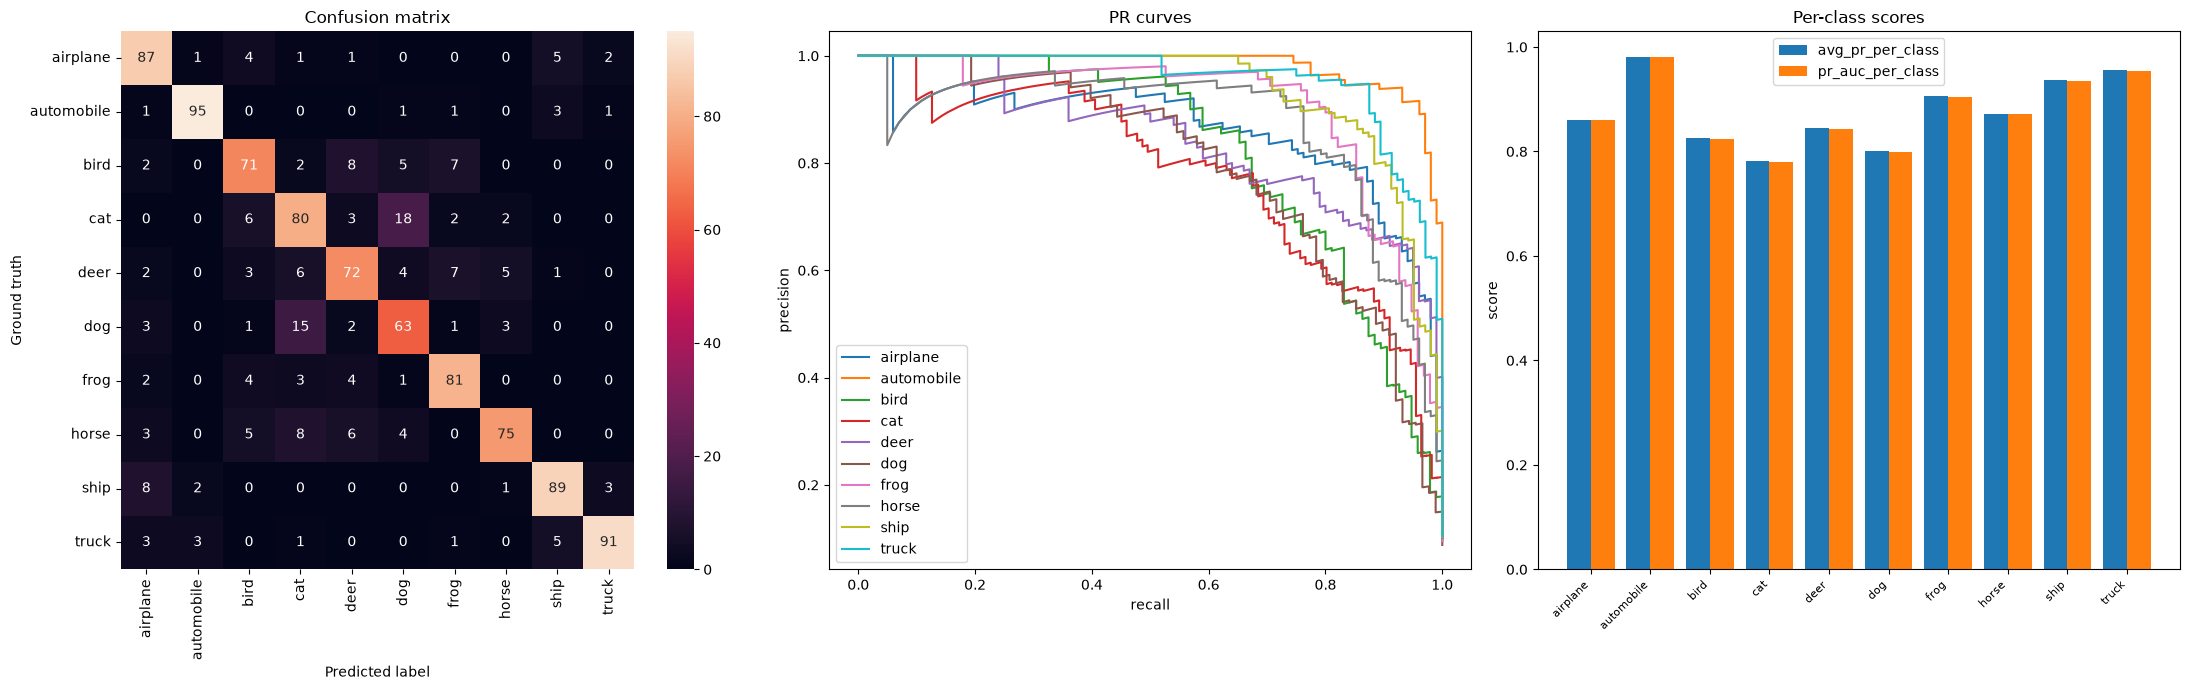

=== ResNetCNN Eval ===
Loss: 0.597059428691864
MCC: 0.7770360037356991
AVG-PR: 0.8874085266946606
PR-AUC: 0.8868866345802265
Classification report
              precision    recall  f1-score   support

    airplane       0.82      0.80      0.81       101
  automobile       0.90      0.95      0.92       102
        bird       0.73      0.69      0.71        95
         cat       0.70      0.66      0.68       111
        deer       0.73      0.74      0.74       100
         dog       0.67      0.75      0.71        88
        frog       0.75      0.86      0.80        95
       horse       0.92      0.75      0.83       101
        ship       0.84      0.90      0.87       103
       truck       0.97      0.88      0.92       104

    accuracy                           0.80      1000
   macro avg       0.80      0.80      0.80      1000
weighted avg       0.80      0.80      0.80      1000

       class   avg_pr   pr_auc
    airplane   0.9091   0.9086
  automobile   0.9717   0.9716
 

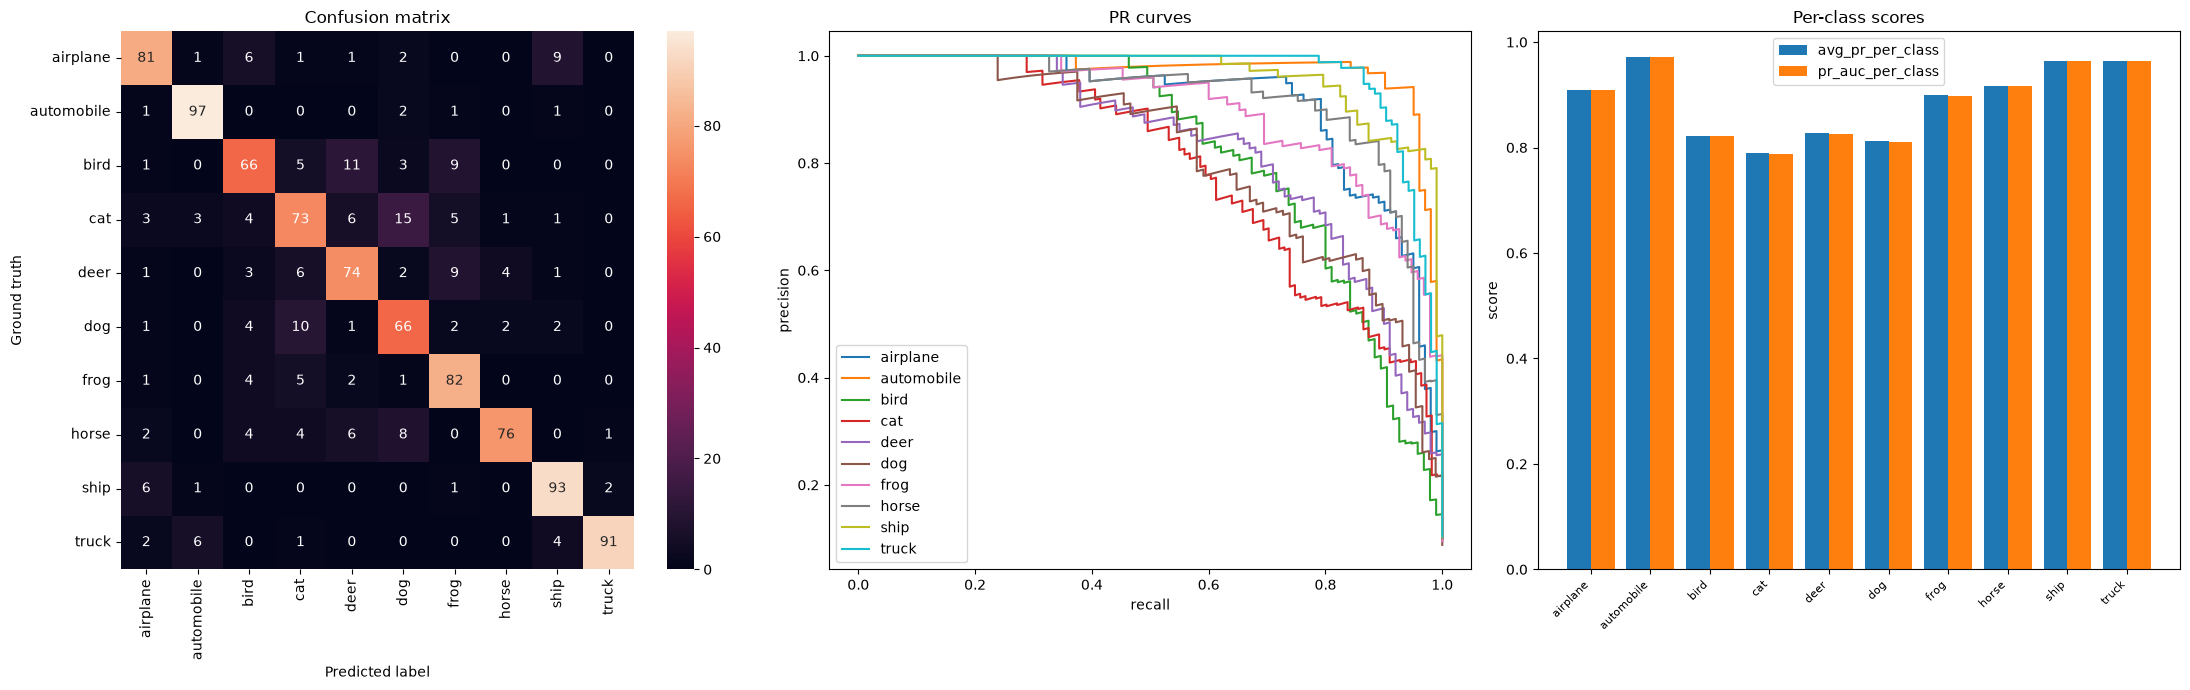

In [ ]:
plain_cnn.eval()
resnet_cnn.eval()
from lab.ai import class_eval

EVAL_BATCH = 512

with torch.no_grad():
    plain_probas = torch.cat([
        plain_cnn(x_test_n[k:k+EVAL_BATCH]).softmax(1)
        for k in range(0, N_TEST, EVAL_BATCH)
    ]).cpu().numpy()
    plain_preds = plain_probas.argmax(1)

    resnet_probas = torch.cat([
        resnet_cnn(x_test_n[k:k+EVAL_BATCH]).softmax(1)
        for k in range(0, N_TEST, EVAL_BATCH)
    ]).cpu().numpy()
    resnet_preds = resnet_probas.argmax(1)

    gts = y_test_t.cpu().numpy()

print("=== PlainCNN Eval ===")
plain_eval, plain_axs = class_eval(gts, plain_preds, plain_probas, classes)
print("=== ResNetCNN Eval ===")
resnet_eval, resnet_axs = class_eval(gts, resnet_preds, resnet_probas, classes)

